In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
DATA_PATH = r"C:\Users\Akshay\OneDrive\Desktop\DMV & ML Practical\DMV Practical\DMV 6\Retail_Sales_Data.csv"

df = pd.read_csv(DATA_PATH)

df.head()

,TransactionID,TransactionDate,Region,ProductCategory,QuantitySold,UnitPrice,SalesAmount
0,RS0001,2025-05-06,North,Electronics,5,13052.75,65263.75
1,RS0002,2025-05-17,South,Electronics,3,17059.11,51177.33
2,RS0003,2025-01-05,North,Groceries,3,401.71,1205.13
3,RS0004,2025-01-27,West,Groceries,1,534.48,534.48
4,RS0005,2025-02-22,North,Electronics,1,12518.23,12518.23


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (320, 7)

Column Names:
['TransactionID', 'TransactionDate', 'Region', 'ProductCategory', 'QuantitySold', 'UnitPrice', 'SalesAmount']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   TransactionID    320 non-null    object 
 1   TransactionDate  320 non-null    object 
 2   Region           320 non-null    object 
 3   ProductCategory  320 non-null    object 
 4   QuantitySold     320 non-null    int64  
 5   UnitPrice        320 non-null    float64
 6   SalesAmount      320 non-null    float64
dtypes: float64(2), int64(1), object(4)
memory usage: 17.6+ KB


In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
TransactionID      0
TransactionDate    0
Region             0
ProductCategory    0
QuantitySold       0
UnitPrice          0
SalesAmount        0
dtype: int64

Duplicate Rows: 0


In [5]:
region_sales = df.groupby("Region")["SalesAmount"].sum().reset_index()

print("Total Sales by Region:")
print(region_sales)

Total Sales by Region:
  Region  SalesAmount
0   East   1698905.09
1  North   1076181.45
2  South   1377072.57
3   West   1284922.31


In [6]:
category_sales = df.groupby("ProductCategory")["SalesAmount"].sum().reset_index()

print("Total Sales by Product Category:")
print(category_sales)

Total Sales by Product Category:
  ProductCategory  SalesAmount
0        Clothing    563799.01
1     Electronics   3364059.90
2       Furniture   1424774.92
3       Groceries     84447.59


In [7]:
average_sales = df.groupby("Region")["SalesAmount"].mean().reset_index()

print("Average Sales by Region:")
print(average_sales)

Average Sales by Region:
  Region   SalesAmount
0   East  18669.286703
1  North  14946.964583
2  South  17000.895926
3   West  16906.872500


In [8]:
category_quantity = df.groupby("ProductCategory")["QuantitySold"].sum().reset_index()

print("Total Quantity Sold by Product Category:")
print(category_quantity)

Total Quantity Sold by Product Category:
  ProductCategory  QuantitySold
0        Clothing           290
1     Electronics           234
2       Furniture           216
3       Groceries           174


In [9]:
top_region = region_sales.loc[region_sales["SalesAmount"].idxmax()]

print("Top Performing Region:")
print(top_region)

Top Performing Region:
Region               East
SalesAmount    1698905.09
Name: 0, dtype: object


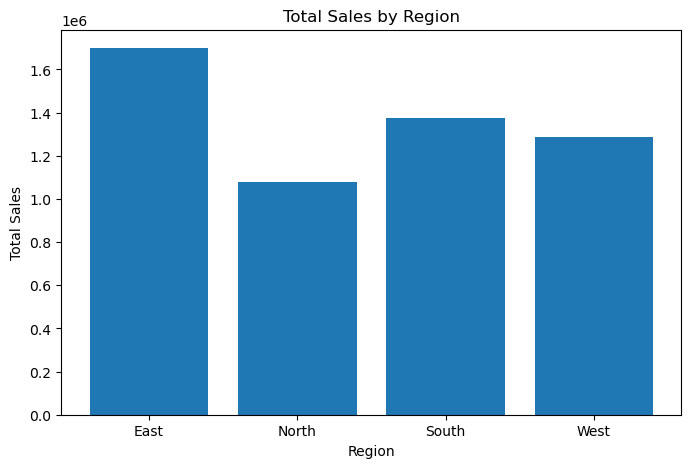

In [10]:
plt.figure(figsize=(8, 5))
plt.bar(region_sales["Region"], region_sales["SalesAmount"])
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.show()

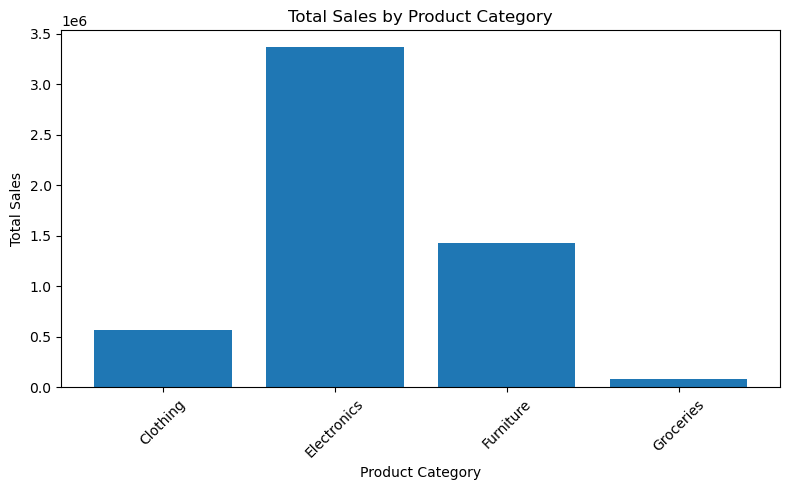

In [11]:
plt.figure(figsize=(8, 5))
plt.bar(category_sales["ProductCategory"], category_sales["SalesAmount"])
plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

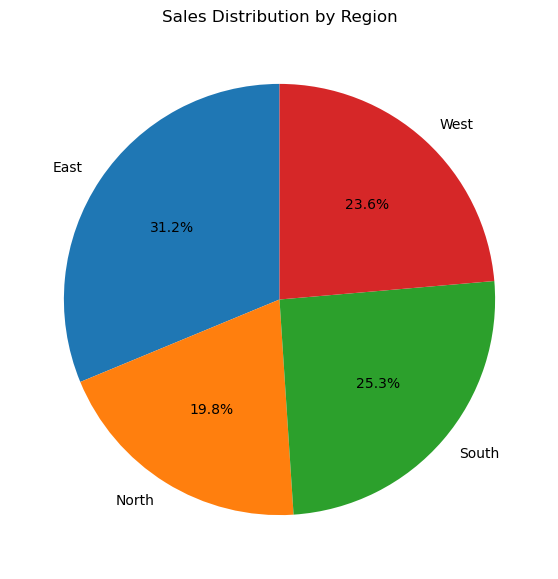

In [12]:
plt.figure(figsize=(7, 7))
plt.pie(region_sales["SalesAmount"], labels=region_sales["Region"], autopct="%1.1f%%", startangle=90)
plt.title("Sales Distribution by Region")
plt.show()

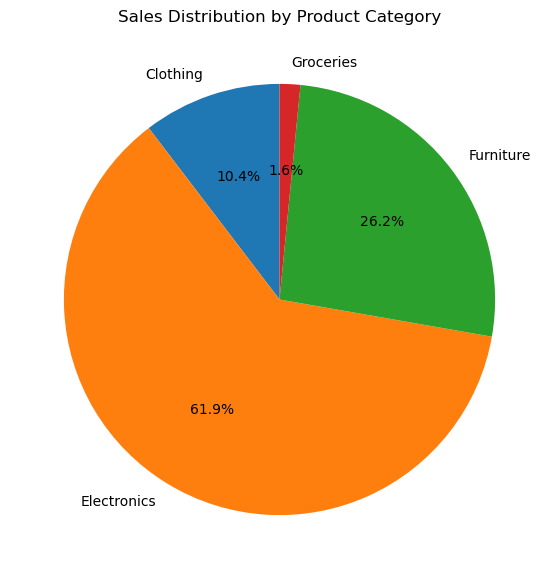

In [13]:
plt.figure(figsize=(7, 7))
plt.pie(category_sales["SalesAmount"], labels=category_sales["ProductCategory"], autopct="%1.1f%%", startangle=90)
plt.title("Sales Distribution by Product Category")
plt.show()

In [14]:
print("Total Sales:", df["SalesAmount"].sum())
print("Average Sales:", df["SalesAmount"].mean())
print("Maximum Sales:", df["SalesAmount"].max())
print("Minimum Sales:", df["SalesAmount"].min())
print("Total Quantity Sold:", df["QuantitySold"].sum())

Total Sales: 5437081.42
Average Sales: 16990.8794375
Maximum Sales: 86494.15
Minimum Sales: 366.98
Total Quantity Sold: 914


In [15]:
OUTPUT_PATH = r"C:\Users\Akshay\OneDrive\Desktop\DMV & ML Practical\DMV Practical\DMV 6"

region_sales.to_csv(OUTPUT_PATH + r"\region_sales.csv", index=False)
category_sales.to_csv(OUTPUT_PATH + r"\category_sales.csv", index=False)
average_sales.to_csv(OUTPUT_PATH + r"\average_sales.csv", index=False)
category_quantity.to_csv(OUTPUT_PATH + r"\category_quantity.csv", index=False)

print("All aggregated reports saved successfully!")

All aggregated reports saved successfully!
